# 03 QCBM Statevector Training

This notebook trains an ideal Quantum Circuit Born Machine using exact statevector simulation.

The workflow is:

```text
SMILES
↓
SELFIES
↓
Token-count latent vectors
↓
KMeans clustering
↓
32 molecular states
↓
Target probability distribution
↓
QCBM statevector training
↓
Learned probability distribution
↓
State sampling
↓
Cluster-based molecular retrieval
↓
Distribution + molecular evaluation

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

print("PROJECT_ROOT =", PROJECT_ROOT)
print("SRC_DIR =", SRC_DIR)

PROJECT_ROOT = d:\QCBM Molecular Augmentation Lite
SRC_DIR = d:\QCBM Molecular Augmentation Lite\src


In [2]:

import os
import time
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

from molaug_qcbm.preprocessing.selfies import (
    safe_selfies
)

from molaug_qcbm.encoding.kmeans import (
    selfies_to_latent,
    KMeansEncoder
)

from molaug_qcbm.encoding.chow_liu import (
    ChowLiuEncoder
)

from molaug_qcbm.qcbm.qcbm import (
    QCBM
)

from molaug_qcbm.qcbm.sampler import (
    QCBMSampler
)

from molaug_qcbm.qcbm.losses import (
    benchmark_losses
)

from molaug_qcbm.augmentation.retrieval import (
    EmpiricalClusterRetriever
)

from molaug_qcbm.evaluation.benchmark_metrics import (
    distribution_report
)

from molaug_qcbm.evaluation.validity import (
    validity_report
)

from molaug_qcbm.evaluation.uniqueness import (
    uniqueness_report
)

from molaug_qcbm.evaluation.novelty import (
    novelty_report
)

from molaug_qcbm.evaluation.qed import (
    qed_report,
    qed_dataframe
)

from molaug_qcbm.evaluation.sa_score import (
    sa_report,
    sa_dataframe
)

from molaug_qcbm.evaluation.syba import (
    syba_report,
    syba_score_smiles
)

from molaug_qcbm.preprocessing.descriptors import (
    descriptor_dataframe,
    compare_descriptor_distributions
)

print("Imports complete.")

Imports complete.


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = r"D:\QCBM Molecular Augmentation Lite"

DATA_DIR = os.path.join(
    PROJECT_ROOT,
    "data"
)

BENCHMARK_DIR = os.path.join(
    DATA_DIR,
    "benchmark_splits"
)

PROCESSED_DIR = os.path.join(
    DATA_DIR,
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "qcbm_statevector"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

TRAIN_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "train.parquet"
)

TEST_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "test.parquet"
)

KNOWN_PARQUET = os.path.join(
    PROCESSED_DIR,
    "known_inhibitors.parquet"
)

N_QUBITS = 5
N_STATES = 2 ** N_QUBITS
N_CLUSTERS = N_STATES

N_LAYERS = 3
ENTANGLEMENT = "linear"
LOSS_METRIC = "mmd"
OPTIMIZER = "COBYLA"
MAXITER = 200

MAX_SELFIES_TOKENS = 32

N_TRAIN_SAMPLE = 20000
N_GENERATED = 4096

print("Qubits:", N_QUBITS)
print("States:", N_STATES)
print("Layers:", N_LAYERS)
print("Optimizer:", OPTIMIZER)
print("Maxiter:", MAXITER)

Qubits: 5
States: 32
Layers: 3
Optimizer: COBYLA
Maxiter: 200


## Experimental Design

The QCBM learns a probability distribution over 32 molecular states.

The molecular states are produced using KMeans clustering over SELFIES token-count vectors.

For 5 qubits:

```text
2^5 = 32 states

In [4]:
train_df = pd.read_parquet(
    TRAIN_PARQUET
)

test_df = pd.read_parquet(
    TEST_PARQUET
)

known_df = pd.read_parquet(
    KNOWN_PARQUET
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Known inhibitors:", known_df.shape)

Train: (808408, 2)
Test: (101051, 2)
Known inhibitors: (636, 6)


In [5]:
train_sample_df = (
    train_df
    .sample(
        n=min(
            N_TRAIN_SAMPLE,
            len(train_df)
        ),
        random_state=SEED
    )
    .reset_index(
        drop=True
    )
)

train_smiles = (
    train_sample_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

test_smiles = (
    test_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

known_smiles = (
    known_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

print("Training sample:", len(train_smiles))
print("Test molecules:", len(test_smiles))
print("Known inhibitor molecules:", len(known_smiles))

Training sample: 20000
Test molecules: 101051
Known inhibitor molecules: 636


In [6]:
train_sample_df["selfies"] = (
    train_sample_df["smiles"]
    .apply(
        safe_selfies
    )
)

train_sample_df = (
    train_sample_df
    .dropna(
        subset=["selfies"]
    )
    .reset_index(
        drop=True
    )
)

train_smiles = (
    train_sample_df["smiles"]
    .astype(str)
    .tolist()
)

train_selfies = (
    train_sample_df["selfies"]
    .astype(str)
    .tolist()
)

print("Valid SELFIES:", len(train_selfies))

train_sample_df.head()

Valid SELFIES: 19992


,id,smiles,selfies
0,954558,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,[C][C][Branch1][C][C][C][=C][C][=C][C][=C][Rin...
1,392394,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,[C][C][C][C][C][C][C][N][Branch2][Ring2][=C][C...
2,585151,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,[C][C][C][=C][Branch2][Ring1][Ring1][C][N][C][...
3,120710,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,[C][C][N][Branch2][Ring1][Branch1][C][C][N][=C...
4,835112,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,[C][C][C][N][C][C][C][C][Ring1][Branch1][C][C]...


In [7]:
X_latent, token_vocab = selfies_to_latent(
    train_selfies,
    max_tokens=MAX_SELFIES_TOKENS
)

print("Latent matrix:", X_latent.shape)
print("Vocabulary size:", len(token_vocab))
print("Token vocabulary:")
print(token_vocab)

Latent matrix: (19992, 32)
Vocabulary size: 32
Token vocabulary:
['[C]', '[=C]', '[Ring1]', '[Branch1]', '[N]', '[=N]', '[O]', '[Ring2]', '[Branch2]', '[=Branch1]', '[F]', '[#Branch1]', '[#Branch2]', '[=Branch2]', '[#C]', '[Cl]', '[P]', '[NH1]', '[S]', '[=Ring1]', '[=O]', '[#N]', '[Br]', '[=Ring2]', '[N-1]', '[O-1]', '[=N-1]', '[O+1]', '[N+1]', '[=S+1]', '[PH1]', '[=O+1]']


## Token-Count Latent Space

Each SELFIES string is converted into a normalized token-count vector.

This representation is chemically safer than raw SMILES tokenization because SELFIES is robust under mutation and decoding.

The token-count representation is then clustered into 32 molecular states.

In [8]:
kmeans_encoder = KMeansEncoder(
    n_clusters=N_CLUSTERS,
    random_state=SEED
)

cluster_ids = kmeans_encoder.fit_predict(
    X_latent
)

target_distribution = kmeans_encoder.target_distribution(
    cluster_ids,
    n_bins=N_STATES
)

train_sample_df["cluster"] = cluster_ids

print("Cluster IDs:", cluster_ids.shape)
print("Target distribution:", target_distribution.shape)
print("Distribution mass:", target_distribution.sum())

train_sample_df["cluster"].value_counts().sort_index()

Cluster IDs: (19992,)
Target distribution: (32,)
Distribution mass: 1.0


cluster
0      560
1      467
2      995
3      264
4      642
5      522
6      668
7      511
8      962
9      994
10    1055
11     462
12     785
13     720
14     642
15     595
16     363
17     822
18     689
19     375
20     706
21     409
22     559
23     454
24     319
25     574
26     396
27     569
28     916
29     665
30     738
31     594
Name: count, dtype: int64

In [9]:
target_distribution_df = pd.DataFrame(
    {
        "state": np.arange(N_STATES),
        "target_probability": target_distribution,
        "count": np.bincount(
            cluster_ids,
            minlength=N_STATES
        )
    }
)

target_distribution_df

,state,target_probability,count
0,0,0.028011,560
1,1,0.023359,467
2,2,0.049770,995
3,3,0.013205,264
4,4,0.032113,642
5,5,0.026110,522
6,6,0.033413,668
7,7,0.025560,511
8,8,0.048119,962
9,9,0.049720,994


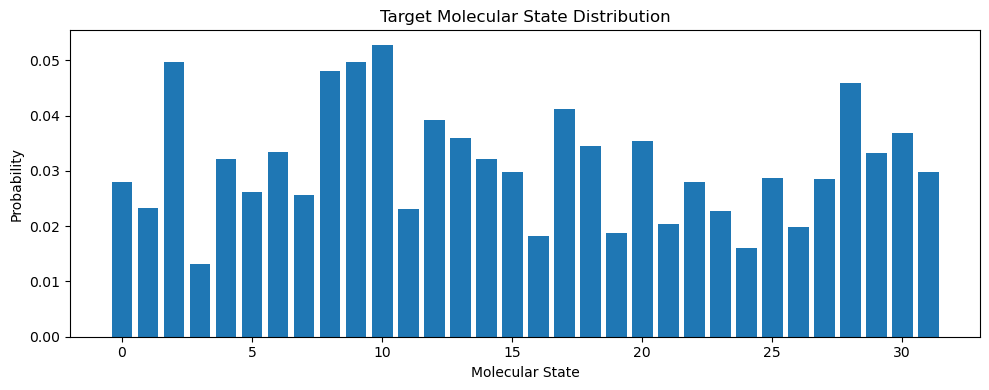

In [10]:
plt.figure(
    figsize=(10, 4)
)

plt.bar(
    target_distribution_df["state"],
    target_distribution_df["target_probability"]
)

plt.xlabel("Molecular State")
plt.ylabel("Probability")
plt.title("Target Molecular State Distribution")
plt.tight_layout()
plt.show()

In [11]:
retriever = EmpiricalClusterRetriever(
    smiles_list=train_smiles,
    cluster_labels=cluster_ids
)

retrieval_report_df = retriever.retrieval_report()

retrieval_report_df

,cluster,count
0,0,560
1,1,467
2,2,995
3,3,264
4,4,642
5,5,522
6,6,668
7,7,511
8,8,962
9,9,994


## Optional Chow-Liu Structure Inspection

Chow-Liu trees estimate pairwise dependency structure between latent dimensions.

This section is diagnostic only. The main statevector QCBM in this notebook uses the standard KMeans state distribution.

The Chow-Liu result will become central in the dedicated Chow-Liu + QCBM notebook.

In [12]:
chow_liu = ChowLiuEncoder()

chow_liu.fit(
    X_latent
)

chow_liu_summary = chow_liu.summary()

print(chow_liu_summary)
print("First 10 Chow-Liu edges:")
print(chow_liu.get_edges()[:10])

{'fitted': True, 'nodes': 32, 'edges': 31}
First 10 Chow-Liu edges:
[(0, 1), (1, 4), (1, 2), (1, 3), (1, 6), (1, 7), (1, 9), (1, 11), (1, 12), (1, 13)]


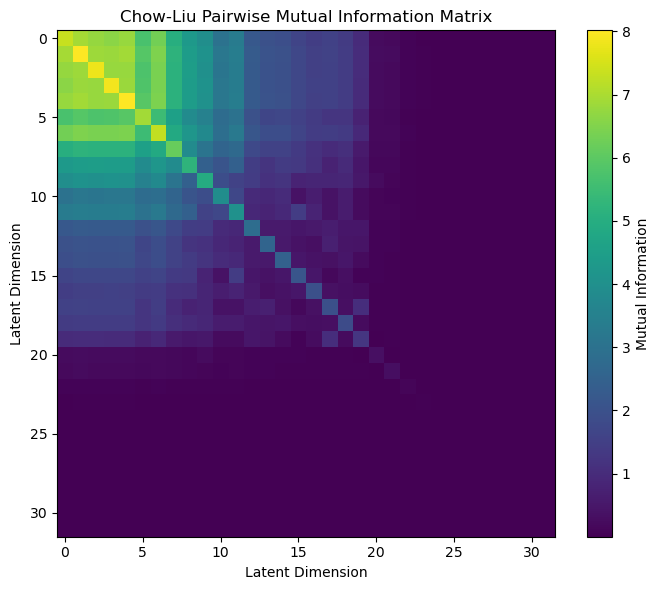

In [13]:
plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    chow_liu.mi_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Mutual Information"
)

plt.title("Chow-Liu Pairwise Mutual Information Matrix")
plt.xlabel("Latent Dimension")
plt.ylabel("Latent Dimension")
plt.tight_layout()
plt.show()

# QCBM Statevector Model

The QCBM is a parameterized quantum circuit whose Born probabilities define a probability distribution over bitstrings.

For 5 qubits, the circuit produces a 32-dimensional probability vector.

The model is trained by minimizing the distance between:

```text
Target KMeans State Distribution

In [14]:
qcbm = QCBM(
    n_qubits=N_QUBITS,
    n_layers=N_LAYERS,
    entanglement=ENTANGLEMENT,
    loss_metric=LOSS_METRIC,
    optimizer=OPTIMIZER,
    maxiter=MAXITER
)

qcbm.summary()

{'trained': False, 'n_qubits': 5, 'n_layers': 3}

In [15]:
n_parameters = qcbm.circuit_builder.parameter_count()

print("Number of parameters:", n_parameters)

initial_theta = np.random.uniform(
    0,
    2 * np.pi,
    n_parameters
)

print("Initial theta shape:", initial_theta.shape)

Number of parameters: 30
Initial theta shape: (30,)


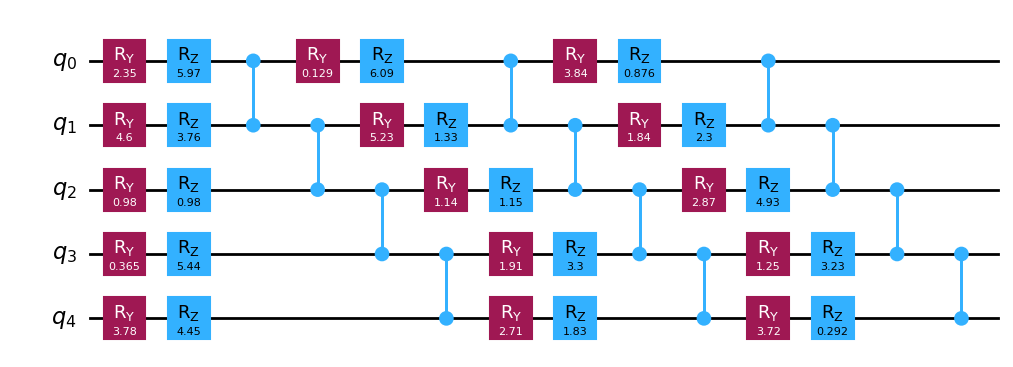

In [16]:
initial_circuit = qcbm.circuit_builder.build(
    initial_theta
)

initial_circuit.draw(
    "mpl"
)

In [17]:
initial_distribution = (
    qcbm.trainer
    .statevector_probabilities(
        initial_theta
    )
)

initial_metrics = benchmark_losses(
    target_distribution,
    initial_distribution
)

initial_metrics

{'KL': 1.409479112600256,
 'TV': 0.6172964740028091,
 'Fidelity': 0.495725266357216,
 'MMD': 0.15412120540230462,
 'Sinkhorn': 4.48120352125403}

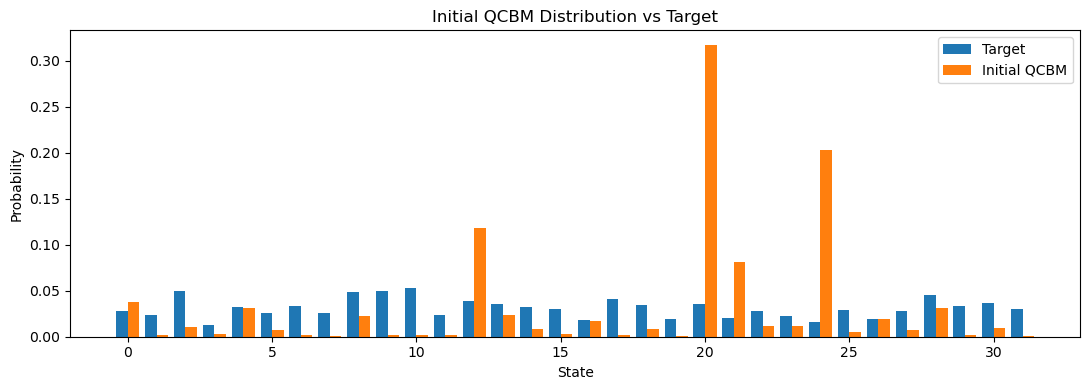

In [18]:
plt.figure(
    figsize=(11, 4)
)

x = np.arange(N_STATES)

plt.bar(
    x - 0.2,
    target_distribution,
    width=0.4,
    label="Target"
)

plt.bar(
    x + 0.2,
    initial_distribution,
    width=0.4,
    label="Initial QCBM"
)

plt.xlabel("State")
plt.ylabel("Probability")
plt.title("Initial QCBM Distribution vs Target")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
start_time = time.perf_counter()

training_result = qcbm.fit(
    target_distribution=target_distribution,
    initial_theta=initial_theta
)

training_time = time.perf_counter() - start_time

print("Training complete.")
print("Training time:", training_time)
print("Best loss:", qcbm.best_loss())
print("Optimizer success:", training_result.success)
print("Optimizer message:", training_result.message)

Training complete.
Training time: 1.543337299997802
Best loss: 0.0024522169426560254
Optimizer success: False
Optimizer message: Return from COBYLA because the objective function has been evaluated MAXFUN times.


In [20]:
qcbm.summary()

{'trained': True,
 'n_qubits': 5,
 'n_layers': 3,
 'best_loss': np.float64(0.0024522169426560254),
 'parameters': 30}

In [21]:
loss_history = qcbm.loss_history()

loss_df = pd.DataFrame(
    {
        "iteration": np.arange(
            len(loss_history)
        ),
        "loss": loss_history
    }
)

loss_df.head()

,iteration,loss
0,0,0.154121
1,1,0.166309
2,2,0.172102
3,3,0.123597
4,4,0.111485


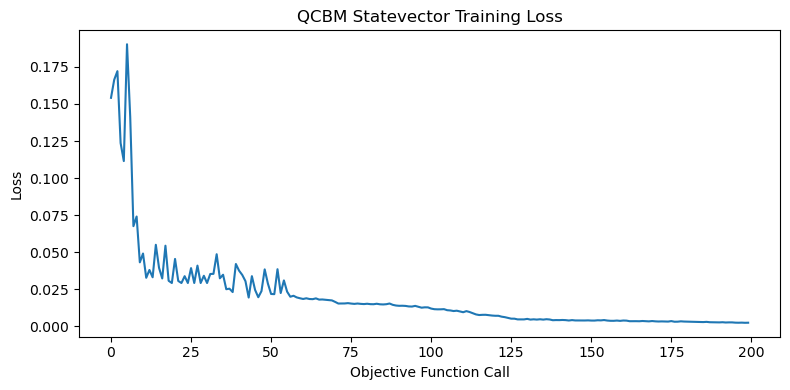

In [22]:
plt.figure(
    figsize=(8, 4)
)

plt.plot(
    loss_df["iteration"],
    loss_df["loss"]
)

plt.xlabel("Objective Function Call")
plt.ylabel("Loss")
plt.title("QCBM Statevector Training Loss")
plt.tight_layout()
plt.show()

In [23]:
learned_distribution = qcbm.probabilities()

print("Learned distribution shape:", learned_distribution.shape)
print("Mass:", learned_distribution.sum())
print("Min probability:", learned_distribution.min())
print("Max probability:", learned_distribution.max())

Learned distribution shape: (32,)
Mass: 1.0
Min probability: 0.008856727779334427
Max probability: 0.06770020510066142


In [24]:
learned_distribution_df = pd.DataFrame(
    {
        "state": np.arange(N_STATES),
        "target_probability": target_distribution,
        "qcbm_probability": learned_distribution,
        "absolute_error": np.abs(
            target_distribution
            -
            learned_distribution
        )
    }
)

learned_distribution_df

,state,target_probability,qcbm_probability,absolute_error
0,0,0.028011,0.027300,0.000711
1,1,0.023359,0.024058,0.000698
2,2,0.049770,0.047481,0.002289
3,3,0.013205,0.026513,0.013307
4,4,0.032113,0.025687,0.006426
5,5,0.026110,0.027118,0.001007
6,6,0.033413,0.046455,0.013042
7,7,0.025560,0.008857,0.016703
8,8,0.048119,0.044577,0.003542
9,9,0.049720,0.040090,0.009630


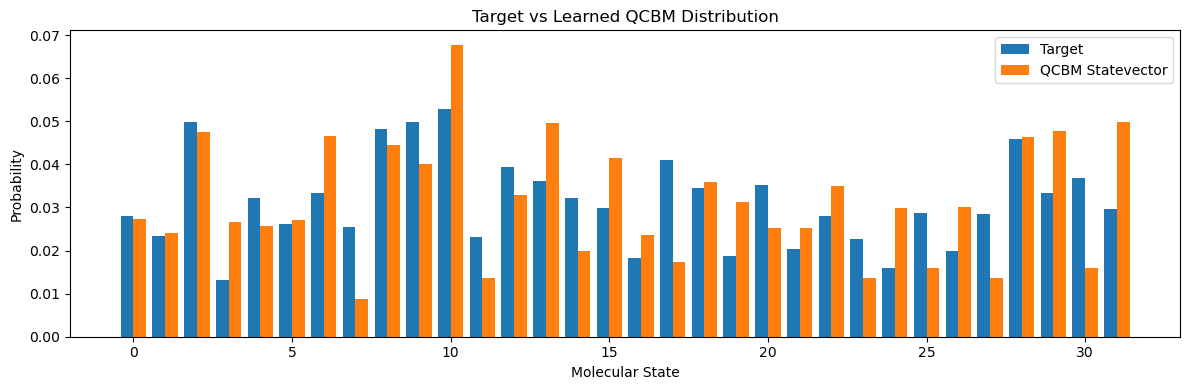

In [25]:
plt.figure(
    figsize=(12, 4)
)

x = np.arange(N_STATES)

plt.bar(
    x - 0.2,
    target_distribution,
    width=0.4,
    label="Target"
)

plt.bar(
    x + 0.2,
    learned_distribution,
    width=0.4,
    label="QCBM Statevector"
)

plt.xlabel("Molecular State")
plt.ylabel("Probability")
plt.title("Target vs Learned QCBM Distribution")
plt.legend()
plt.tight_layout()
plt.show()

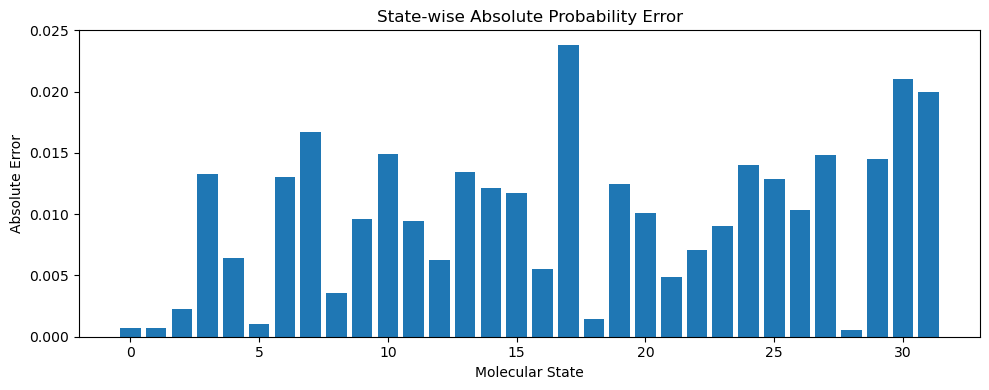

In [26]:
plt.figure(
    figsize=(10, 4)
)

plt.bar(
    learned_distribution_df["state"],
    learned_distribution_df["absolute_error"]
)

plt.xlabel("Molecular State")
plt.ylabel("Absolute Error")
plt.title("State-wise Absolute Probability Error")
plt.tight_layout()
plt.show()

In [27]:
statevector_distribution_metrics = distribution_report(
    "QCBM_Statevector",
    learned_distribution,
    target_distribution
)

statevector_distribution_metrics

{'method': 'QCBM_Statevector',
 'KL': 0.08517762045904992,
 'TV': 0.15889779607243926,
 'Fidelity': 0.9600096480263132,
 'MMD': 0.0024522169426560254,
 'Sinkhorn': 0.23146195583603055}

In [28]:
initial_metrics_named = {
    "method": "Initial_QCBM",
    **initial_metrics
}

final_metrics_named = {
    "method": "QCBM_Statevector",
    **benchmark_losses(
        target_distribution,
        learned_distribution
    )
}

statevector_comparison_df = pd.DataFrame(
    [
        initial_metrics_named,
        final_metrics_named
    ]
)

statevector_comparison_df

,method,KL,TV,Fidelity,MMD,Sinkhorn
0,Initial_QCBM,1.409479,0.617296,0.495725,0.154121,4.481204
1,QCBM_Statevector,0.085178,0.158898,0.960010,0.002452,0.231462


In [29]:
np.save(
    os.path.join(
        RESULTS_DIR,
        "target_distribution.npy"
    ),
    target_distribution
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_distribution.npy"
    ),
    learned_distribution
)

np.save(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_parameters.npy"
    ),
    qcbm.parameters()
)

loss_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_loss_history.csv"
    ),
    index=False
)

learned_distribution_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_distribution_table.csv"
    ),
    index=False
)

statevector_comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_distribution_metrics.csv"
    ),
    index=False
)

print("Distribution outputs saved.")

Distribution outputs saved.


# Sampling from the Trained QCBM

The statevector model gives an exact probability distribution.

To simulate a shot-based quantum experiment, we sample discrete states from the learned distribution.

This mirrors the IBM hardware setting where the circuit returns bitstring counts after measurement.

In [30]:
sampled_states = qcbm.sample_states(
    n_samples=N_GENERATED,
    random_state=SEED
)

sampled_state_counts = np.bincount(
    sampled_states,
    minlength=N_STATES
)

sampled_distribution = (
    sampled_state_counts
    /
    sampled_state_counts.sum()
)

print("Sampled states:", sampled_states.shape)
print("Sampled distribution mass:", sampled_distribution.sum())

Sampled states: (4096,)
Sampled distribution mass: 1.0


In [31]:
sampled_distribution_metrics = distribution_report(
    "QCBM_Statevector_Sampled",
    sampled_distribution,
    target_distribution
)

sampled_distribution_metrics

{'method': 'QCBM_Statevector_Sampled',
 'KL': 0.0890413932789566,
 'TV': 0.16090098148634455,
 'Fidelity': 0.9585632415035173,
 'MMD': 0.0025783186446366735,
 'Sinkhorn': 0.2503537547831636}

In [32]:
sampled_counts_df = pd.DataFrame(
    {
        "state": np.arange(N_STATES),
        "count": sampled_state_counts,
        "sampled_probability": sampled_distribution,
        "target_probability": target_distribution,
        "qcbm_probability": learned_distribution
    }
)

sampled_counts_df

,state,count,sampled_probability,target_probability,qcbm_probability
0,0,99,0.024170,0.028011,0.027300
1,1,106,0.025879,0.023359,0.024058
2,2,197,0.048096,0.049770,0.047481
3,3,112,0.027344,0.013205,0.026513
4,4,114,0.027832,0.032113,0.025687
5,5,124,0.030273,0.026110,0.027118
6,6,189,0.046143,0.033413,0.046455
7,7,35,0.008545,0.025560,0.008857
8,8,186,0.045410,0.048119,0.044577
9,9,163,0.039795,0.049720,0.040090


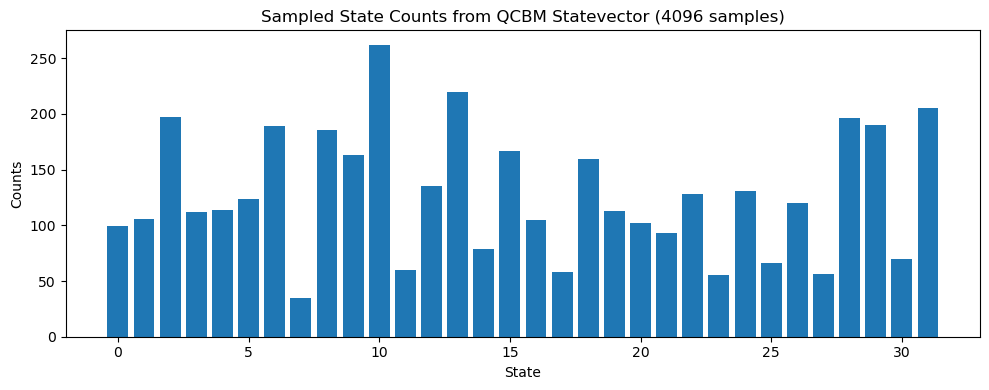

In [33]:
plt.figure(
    figsize=(10, 4)
)

plt.bar(
    sampled_counts_df["state"],
    sampled_counts_df["count"]
)

plt.xlabel("State")
plt.ylabel("Counts")
plt.title(f"Sampled State Counts from QCBM Statevector ({N_GENERATED} samples)")
plt.tight_layout()
plt.show()

In [34]:
generated_smiles = retriever.retrieve_batch(
    sampled_states,
    random_state=SEED
)

generated_smiles = [
    smi
    for smi in generated_smiles
    if smi is not None
]

print("Retrieved molecules:", len(generated_smiles))

generated_df = pd.DataFrame(
    {
        "method": "QCBM_Statevector",
        "smiles": generated_smiles
    }
)

generated_df.head()

Retrieved molecules: 4096


,method,smiles
0,QCBM_Statevector,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F
1,QCBM_Statevector,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...
2,QCBM_Statevector,C=CCCCOc1nc2c([nH]1)CCN(c1ccccc1CCCC)C2
3,QCBM_Statevector,CN1CC(Oc2[nH]c3c(c2N2CCCCC2)CCN(c2cncc4ccccc24...
4,QCBM_Statevector,CC(NCc1ccnc(OCC2CCCN2C)n1)=C1CC=NNC1


In [35]:
validity_stats = validity_report(
    generated_smiles
)

validity_stats

{'total': 4096,
 'valid': 4096,
 'invalid': 0,
 'validity': 1.0,
 'validity_percent': 100.0}

In [36]:
uniqueness_stats = uniqueness_report(
    generated_smiles
)

uniqueness_stats

{'total': 4096,
 'unique': 3676,
 'duplicates': 420,
 'uniqueness': 0.8974609375,
 'uniqueness_percent': 89.74609375}

In [37]:
novelty_stats = novelty_report(
    generated_smiles,
    train_smiles
)

novelty_stats

{'generated': 4096,
 'novel': 0,
 'seen': 4096,
 'novelty': 0.0,
 'novelty_percent': 0.0}

In [38]:
qed_stats = qed_report(
    generated_smiles
)

qed_stats

{'n_molecules': 4096,
 'mean_qed': 0.6045960144424705,
 'median_qed': 0.5936095409142323,
 'max_qed': 0.9427335596607995,
 'min_qed': 0.1464187608007447}

In [39]:
sa_stats = sa_report(
    generated_smiles
)

sa_stats

{'n_molecules': 4096,
 'mean_sa': 3.7640896308016436,
 'median_sa': 3.7911895843422947,
 'std_sa': 0.4481204919673015,
 'min_sa': 2.345812500246561,
 'max_sa': 5.636156130486972}

In [40]:
syba_stats = syba_report(
    generated_smiles
)

syba_stats

{'n_molecules': 4096,
 'mean': 22.88764715840371,
 'std': 18.172256055763267,
 'min': -62.592962463244554,
 'max': 108.85998989427549,
 'median': 18.8720327966246}

In [41]:
molecular_quality_df = pd.DataFrame(
    [
        {
            "method": "QCBM_Statevector",
            "generated": len(generated_smiles),
            "validity": validity_stats["validity"],
            "uniqueness": uniqueness_stats["uniqueness"],
            "novelty": novelty_stats["novelty"],
            "mean_qed": qed_stats["mean_qed"],
            "median_qed": qed_stats["median_qed"],
            "mean_sa": sa_stats["mean_sa"],
            "median_sa": sa_stats["median_sa"],
            "mean_syba": syba_stats["mean"],
            "median_syba": syba_stats["median"],
            "training_time_sec": training_time
        }
    ]
)

molecular_quality_df

,method,generated,validity,uniqueness,novelty,mean_qed,median_qed,mean_sa,median_sa,mean_syba,median_syba,training_time_sec
0,QCBM_Statevector,4096,1.0,0.897461,0.0,0.604596,0.59361,3.76409,3.79119,22.887647,18.872033,1.543337


In [42]:
qed_df = qed_dataframe(
    generated_smiles
)

sa_df = sa_dataframe(
    generated_smiles
)

syba_scores = [
    syba_score_smiles(
        smi
    )
    for smi in generated_smiles
]

syba_df = pd.DataFrame(
    {
        "SMILES": generated_smiles,
        "SYBA": syba_scores
    }
)

molecule_score_df = (
    qed_df
    .merge(
        sa_df,
        on="SMILES",
        how="left"
    )
    .merge(
        syba_df,
        on="SMILES",
        how="left"
    )
)

molecule_score_df.head()

,SMILES,QED,SA_Score,SYBA
0,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F,0.543344,3.228768,33.695302
1,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569
2,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569
3,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569
4,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569


In [43]:
qed_df = qed_dataframe(
    generated_smiles
)

sa_df = sa_dataframe(
    generated_smiles
)

syba_scores = [
    syba_score_smiles(
        smi
    )
    for smi in generated_smiles
]

syba_df = pd.DataFrame(
    {
        "SMILES": generated_smiles,
        "SYBA": syba_scores
    }
)

molecule_score_df = (
    qed_df
    .merge(
        sa_df,
        on="SMILES",
        how="left"
    )
    .merge(
        syba_df,
        on="SMILES",
        how="left"
    )
)

molecule_score_df.head()

,SMILES,QED,SA_Score,SYBA
0,CN(Cc1cnc(C2CCCCC2)nc1)OCC=CCC(F)(F)F,0.543344,3.228768,33.695302
1,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569
2,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569
3,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569
4,Cc1cccc(F)c1-c1ncc2c(c1C)N=C(OCCc1nccn1C)NN2N1...,0.589188,4.069114,0.825569


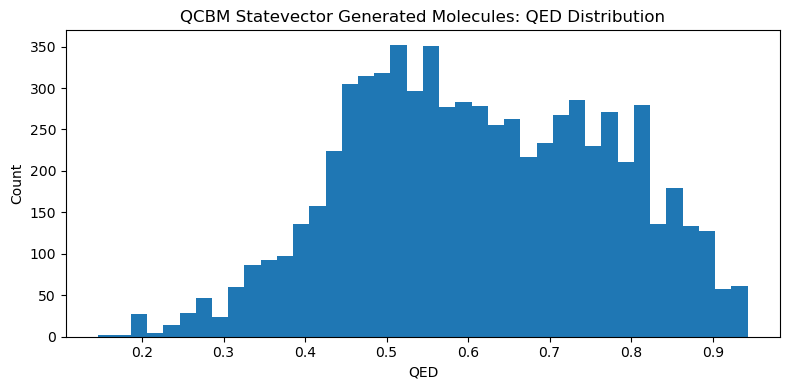

In [44]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    molecule_score_df["QED"].dropna(),
    bins=40
)

plt.xlabel("QED")
plt.ylabel("Count")
plt.title("QCBM Statevector Generated Molecules: QED Distribution")
plt.tight_layout()
plt.show()

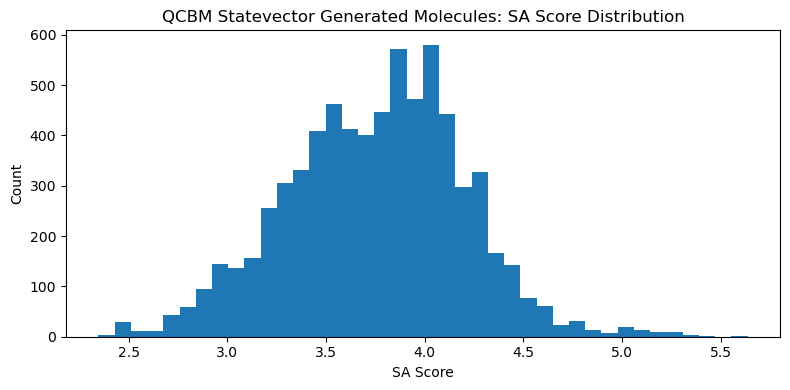

In [45]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    molecule_score_df["SA_Score"].dropna(),
    bins=40
)

plt.xlabel("SA Score")
plt.ylabel("Count")
plt.title("QCBM Statevector Generated Molecules: SA Score Distribution")
plt.tight_layout()
plt.show()

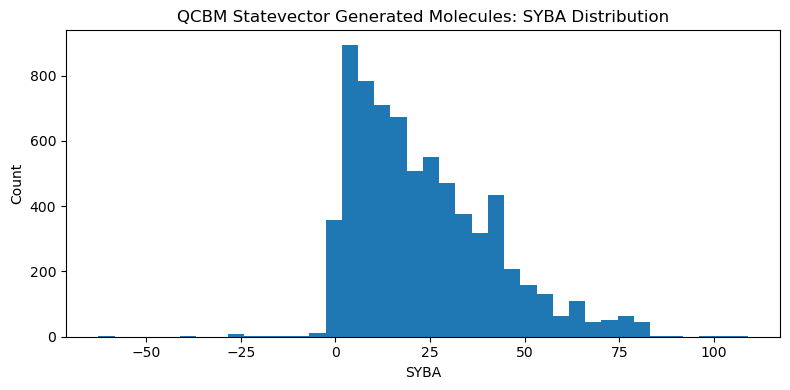

In [46]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    molecule_score_df["SYBA"].dropna(),
    bins=40
)

plt.xlabel("SYBA")
plt.ylabel("Count")
plt.title("QCBM Statevector Generated Molecules: SYBA Distribution")
plt.tight_layout()
plt.show()

In [47]:
descriptor_comparison_df = compare_descriptor_distributions(
    training_smiles=train_smiles[:2000],
    generated_smiles=generated_smiles[:2000]
)

descriptor_comparison_df

,Descriptor,Training Mean,Generated Mean
0,MolWt,423.455990,417.179154
1,LogP,3.646489,3.616490
2,TPSA,67.791970,66.850705
3,HBD,1.313000,1.330000
4,HBA,6.138500,5.969000
5,RotatableBonds,6.695500,6.670000
6,RingCount,4.417000,4.260500
7,HeavyAtoms,30.518500,30.025500


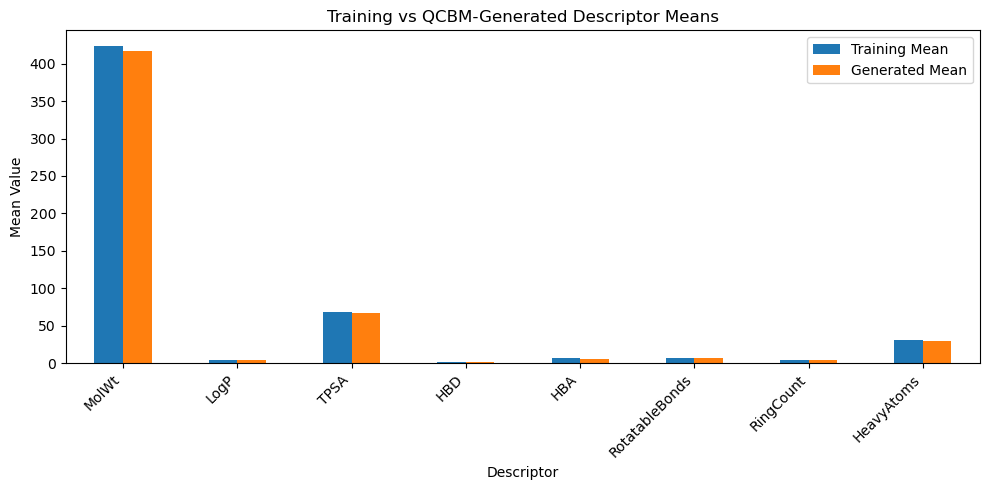

In [48]:
descriptor_comparison_df.set_index(
    "Descriptor"
)[
    [
        "Training Mean",
        "Generated Mean"
    ]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Mean Value")
plt.title("Training vs QCBM-Generated Descriptor Means")
plt.xticks(
    rotation=45,
    ha="right"
)
plt.tight_layout()
plt.show()

In [49]:
generated_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_generated_smiles.csv"
    ),
    index=False
)

sampled_counts_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_sampled_counts.csv"
    ),
    index=False
)

molecular_quality_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_molecular_quality.csv"
    ),
    index=False
)

molecule_score_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_molecule_scores.csv"
    ),
    index=False
)

descriptor_comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_descriptor_comparison.csv"
    ),
    index=False
)

print("Molecular outputs saved.")

Molecular outputs saved.


In [50]:
final_benchmark_df = pd.DataFrame(
    [
        {
            **statevector_distribution_metrics,
            "generated": len(generated_smiles),
            "validity": validity_stats["validity"],
            "uniqueness": uniqueness_stats["uniqueness"],
            "novelty": novelty_stats["novelty"],
            "mean_qed": qed_stats["mean_qed"],
            "mean_sa": sa_stats["mean_sa"],
            "mean_syba": syba_stats["mean"],
            "training_time_sec": training_time
        }
    ]
)

final_benchmark_df

,method,KL,TV,Fidelity,MMD,Sinkhorn,generated,validity,uniqueness,novelty,mean_qed,mean_sa,mean_syba,training_time_sec
0,QCBM_Statevector,0.085178,0.158898,0.96001,0.002452,0.231462,4096,1.0,0.897461,0.0,0.604596,3.76409,22.887647,1.543337


In [51]:
final_benchmark_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "qcbm_statevector_final_benchmark.csv"
    ),
    index=False
)

print("Final benchmark saved.")

Final benchmark saved.


# Research Interpretation

The statevector QCBM represents the ideal quantum generative model before hardware noise.

## What this notebook establishes

1. Whether the QCBM ansatz can learn the empirical molecular-state distribution.
2. Whether the learned Born distribution improves over random initialization.
3. Whether sampled quantum states retrieve chemically meaningful molecules.
4. Whether the retrieved molecules preserve validity, uniqueness, novelty, QED, SA, and SYBA quality.
5. Whether the model is competitive enough to justify IBM hardware execution.

## Important limitation

This notebook does not generate molecules by decoding quantum states directly.

It performs retrieval-based molecular generation:

```text
Quantum state
↓
KMeans cluster
↓
Empirical molecule retrieval

In [52]:
print("=" * 80)
print("QCBM STATEVECTOR NOTEBOOK COMPLETE")
print("=" * 80)

print("\nDistribution Metrics")
display(
    final_benchmark_df[
        [
            "method",
            "KL",
            "TV",
            "Fidelity",
            "MMD",
            "Sinkhorn"
        ]
    ]
)

print("\nMolecular Quality")
display(
    final_benchmark_df[
        [
            "method",
            "validity",
            "uniqueness",
            "novelty",
            "mean_qed",
            "mean_sa",
            "mean_syba"
        ]
    ]
)

print("\nOutputs saved to:")
print(RESULTS_DIR)

QCBM STATEVECTOR NOTEBOOK COMPLETE

Distribution Metrics


,method,KL,TV,Fidelity,MMD,Sinkhorn
0,QCBM_Statevector,0.085178,0.158898,0.96001,0.002452,0.231462



Molecular Quality


,method,validity,uniqueness,novelty,mean_qed,mean_sa,mean_syba
0,QCBM_Statevector,1.0,0.897461,0.0,0.604596,3.76409,22.887647



Outputs saved to:
D:\QCBM Molecular Augmentation Lite\results\qcbm_statevector


# Notebook Outputs

This notebook produced:

```text
results/qcbm_statevector/

├── target_distribution.npy
├── qcbm_statevector_distribution.npy
├── qcbm_statevector_parameters.npy
├── qcbm_statevector_loss_history.csv
├── qcbm_statevector_distribution_table.csv
├── qcbm_statevector_distribution_metrics.csv
├── qcbm_statevector_sampled_counts.csv
├── qcbm_statevector_generated_smiles.csv
├── qcbm_statevector_molecular_quality.csv
├── qcbm_statevector_molecule_scores.csv
├── qcbm_statevector_descriptor_comparison.csv
├── qcbm_statevector_final_benchmark.csv